# Lecture 18 — Randomised methods for large matrices

We generate 4096 snapshots of the Gray–Scott simulation from L17. Our goal is to describe their changing concentration pattern with a few fixed spatial modes and time-dependent weights.

We compare a full eigendecomposition with the **randomised SVD recurrence used in the coursework**, implemented here with NumPy. We check the approximation, count its operations and memory transfers, and interpret measured execution times.

[Notes](https://teaching.borisbolliet.io/c1-2026/materials/class18/notes.pdf) · [Interactive reconstruction](https://teaching.borisbolliet.io/c1-2026/animations/class18-modes/)

Run the cells in order with NumPy and Matplotlib installed. All functions are included below. Live timings depend on the machine. The snapshot array occupies 512 MiB; allow a few GB for the full calculation and its intermediate arrays.

In [1]:
%matplotlib inline
import math
import statistics
import time
import numpy as np
import matplotlib.pyplot as plt


def seconds(fn, *args, repeat=3):
    """Median of repeated calls after one untimed warm-up."""
    fn(*args)
    times = []
    for _ in range(repeat):
        start = time.perf_counter()
        fn(*args)
        times.append(time.perf_counter() - start)
    return statistics.median(times)

## 1. Low rank in data

### Snapshots and their Gram matrix

Rows of $X$ hold $n$ samples; its $p$ columns hold measured variables. Subtracting the mean row gives the centred matrix $X_c$ (written $\tilde X$ in the notes). The superscript $T$ denotes transpose, which exchanges rows and columns.

An **inner product** multiplies corresponding entries of two vectors and sums the products. The **Gram matrix** $A=X_cX_c^T/p$ contains these products for pairs of centred samples: $A_{ij}=\sum_{r=1}^p(X_c)_{ir}(X_c)_{jr}/p$. Here $i,j$ label samples and $r$ labels a measured variable. Its shape is $n\times n$.

$A$ is symmetric, meaning $A_{ij}=A_{ji}$. It is also **positive semi-definite**: $z^TAz\geq0$ for every real vector $z$ of length $n$.

For two samples of three values, the mean is $(2,3,4)$. The centred rows are $(-1,-1,-1)$ and $(1,1,1)$, so $A$ should be `[[1, -1], [-1, 1]]`.

In [2]:
def gram(X):
    """The (n, n) matrix Xc Xc^T / p of the (n, p) array X, where Xc is X minus its mean row.

    Examples
    --------
    >>> gram(np.array([[1.0, 2.0], [3.0, 2.0]]))
    array([[ 0.5, -0.5],
           [-0.5,  0.5]])
    """
    Xc = X - X.mean(axis=0)
    return Xc @ Xc.T / X.shape[1]

small = np.array([[1., 2., 3.], [3., 4., 5.]])
print(gram(small))
np.testing.assert_allclose(gram(small), [[1., -1.], [-1., 1.]])

[[ 1. -1.]
 [-1.  1.]]


We now generate the same run as the notes: a $128\times128$ grid, parameters $(F,k)=(0.030,0.062)$, 8192 Euler steps of size 1, and a snapshot after every second step. Each snapshot becomes one row with 16,384 entries. The functions below reuse the stencil and time step from L17.

In [3]:
def laplacian(a):
    """Five-point Laplacian over the last two axes of a, with periodic boundaries.

    Parameters
    ----------
    a : numpy.ndarray
        Array of shape (..., n0, n1); the axes before the last two are a batch.

    Returns
    -------
    numpy.ndarray
        Array of the same shape as ``a``.

    Examples
    --------
    >>> a = np.zeros((3, 3)); a[1, 1] = 1.0
    >>> print(laplacian(a))
    [[ 0.  1.  0.]
     [ 1. -4.  1.]
     [ 0.  1.  0.]]
    """
    pad = [(0, 0)] * (a.ndim - 2) + [(1, 1), (1, 1)]
    p = np.pad(a, pad, mode="wrap")   # one layer of periodic copies around each grid
    return (p[..., :-2, 1:-1] + p[..., 2:, 1:-1]
            + p[..., 1:-1, :-2] + p[..., 1:-1, 2:] - 4 * a)

def initial(n, seed=0, batch=()):
    """u = 1 and v = 0, except a central square of u = 0.5 and v = 0.25, with bounded noise in that square.

    ``batch`` is the shape of the batch axes; every grid of the batch starts
    from different noise.
    """
    rng = np.random.default_rng(seed)
    u, v = np.ones(batch + (n, n)), np.zeros(batch + (n, n))
    c = slice(n // 2 - 8, n // 2 + 8)
    u[..., c, c], v[..., c, c] = 0.50, 0.25
    u[..., c, c] += rng.uniform(-0.01, 0.01, u[..., c, c].shape)
    v[..., c, c] += rng.uniform(-0.01, 0.01, v[..., c, c].shape)
    return u, v

def step(u, v, F, k, Du=0.16, Dv=0.08, dt=1.0):
    """One forward Euler step of the Gray-Scott equations; returns new arrays.

    F and k are numbers, or arrays that broadcast against u and v.
    The pure-diffusion Euler bound is max(Du, Dv) * dt <= 1/4.
    Reactions can impose an additional restriction.
    """
    uvv = u * v * v
    return (u + dt * (Du * laplacian(u) - uvv + F * (1 - u)),
            v + dt * (Dv * laplacian(v) + uvv - (F + k) * v))

def snapshots(F, k, count=4096, every=2, grid=128, seed=0):
    """The field v of one Gray-Scott run, recorded every `every` steps.

    Returns an array of shape (count, grid * grid). Row i holds v after
    (i + 1) * every steps, flattened in row-major order.

    Examples
    --------
    >>> snapshots(0.030, 0.062, count=3, every=1, grid=16).shape
    (3, 256)
    """
    u, v = initial(grid, seed)
    X = np.empty((count, grid * grid))
    for i in range(count):
        for _ in range(every):
            u, v = step(u, v, F, k)
        X[i] = v.ravel()
    return X

X = snapshots(0.030, 0.062, count=4096, every=2, grid=128)
A = gram(X)
print('X:', X.shape, X.nbytes / 2**20, 'MiB')
print('A:', A.shape, A.nbytes / 2**20, 'MiB')
assert np.array_equal(A, A.T)

X: (4096, 16384) 512.0 MiB
A: (4096, 4096) 128.0 MiB


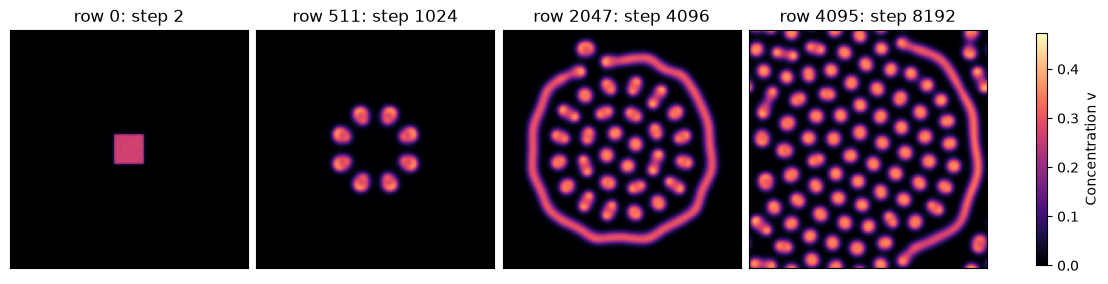

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3), layout='constrained')
for ax, i in zip(axes, [0, 511, 2047, 4095]):
    im = ax.imshow(X[i].reshape(128, 128), origin='lower', cmap='magma', vmin=0, vmax=X.max())
    ax.set(title=f'row {i}: step {2*(i+1)}', xticks=[], yticks=[])
fig.colorbar(im, ax=axes, label='Concentration v', shrink=.8)
plt.show()

### Memory requirements

In float64, $X$ occupies $8np$ bytes and $A$ occupies $8n^2$ bytes. On a computer with 128 GiB RAM, suppose we allocate 64 GB to these arrays. The positive root of $8n^2+8pn=64\times10^9$, rounded down, gives the largest $n$ for that budget. This count excludes workspace and additional copies.

In [5]:
p, budget = 16384, 64e9
n_max = math.floor((-8*p + math.sqrt((8*p)**2 + 32*budget)) / 16)
print('maximum n:', n_max)
print('X and A in GB:', 8*n_max*p/1e9, 8*n_max**2/1e9)
assert 8*n_max*p + 8*n_max**2 <= budget
assert 8*(n_max+1)*p + 8*(n_max+1)**2 > budget

maximum n: 81625
X and A in GB: 10.698752 53.301125


### Leading eigenvectors and the order of `eigh`

An **eigenvector** $u_i\ne0$ satisfies $Au_i=\lambda_i u_i$; the **eigenvalue** $\lambda_i$ is the scaling factor. For our symmetric matrix we can choose **orthonormal** eigenvectors: mutually perpendicular and each of length one. Positive semi-definite matrices have non-negative eigenvalues.

We keep $k$ vectors belonging to the largest eigenvalues. NumPy's `eigh` returns **ascending** eigenvalues, with `U[:, i]` paired with `w[i]`. Reversing both selects the leading components in descending order. A vector and its negative are both valid eigenvectors of the same eigenvalue.

NumPy delegates the eigendecomposition to [LAPACK](https://www.netlib.org/lapack/) (Linear Algebra PACKage), a library of compiled Fortran routines. LAPACK calls [BLAS](https://www.netlib.org/blas/) (Basic Linear Algebra Subprograms) for operations such as matrix products, using implementations optimised for the processor. The reference BLAS implementation is also written in Fortran.

In [6]:
def leading_eigh(A, k):
    """The k largest eigenvalues of the symmetric matrix A, largest first, and their eigenvectors.

    np.linalg.eigh returns the eigenvalues in ascending order, with the
    eigenvector of w[i] in column U[:, i]. Reversing both puts the largest first.

    Examples
    --------
    >>> w, U = leading_eigh(np.array([[2.0, 1.0], [1.0, 2.0]]), 1)
    >>> w
    array([3.])
    >>> np.abs(U).round(4)
    array([[0.7071],
           [0.7071]])
    """
    w, U = np.linalg.eigh(A)           # ascending order
    return w[::-1][:k], U[:, ::-1][:, :k]

C = np.array([[2., 1., 0.], [1., 2., 0.], [0., 0., 5.]])
w, U = np.linalg.eigh(C)
print('ascending eigenvalues:', w)
print('leading two:', w[::-1][:2])
np.testing.assert_allclose(C @ U, U * w)

w_all, U_all = np.linalg.eigh(A)
lam, U_ref = w_all[::-1], U_all[:, ::-1][:, :10]
share = np.cumsum(lam) / lam.sum()
print(f'ten modes retain {100*share[9]:.1f}% of the variation')
assert abs(share[9] - .951016836) < 1e-7

ascending eigenvalues: [1. 3. 5.]
leading two: [5. 3.]


ten modes retain 95.1% of the variation


### Spatial modes and reconstruction

The vector $u_i$ has one weight per snapshot: entry $(u_i)_j$ is the weight of mode $i$ in snapshot $j$. The spatial mode $X_c^Tu_i$ has one value per grid point. We reconstruct a centred snapshot by summing these fixed maps with that snapshot's weights, then add the mean back.

A matrix's **rank** is the largest number of independent columns we can select. Independent columns cannot be written as weighted sums of the others in the set. For example, $(1,0)$ and $(0,1)$ are independent; adding their sum $(1,1)$ does not increase the rank. A reconstruction from $k$ fixed maps has rank at most $k$.

The **trace** is the sum of the diagonal entries. For $A$ it also equals the sum of the eigenvalues and the total squared centred values divided by $p$. The fraction $\sum_{i=1}^k\lambda_i/\sum_{i=1}^n\lambda_i$ tells us how much variation the retained modes describe.

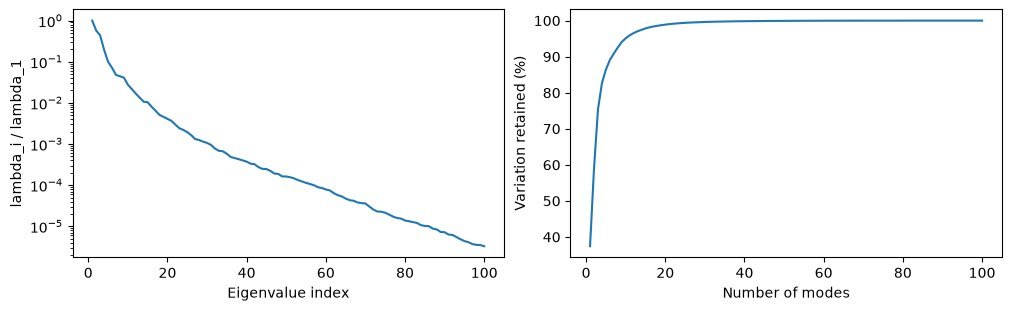

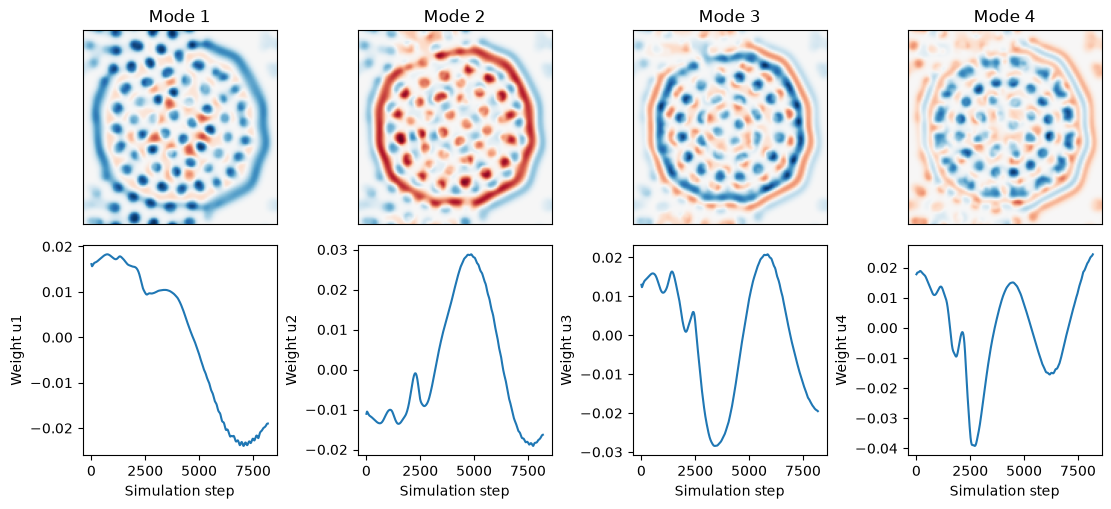

In [7]:
mean = X.mean(axis=0)
Xc = X - mean
spatial = Xc.T @ U_ref
steps = 2*np.arange(1, len(X)+1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout='constrained')
axes[0].semilogy(np.arange(1, 101), lam[:100]/lam[0])
axes[0].set(xlabel='Eigenvalue index', ylabel='lambda_i / lambda_1')
axes[1].plot(np.arange(1, 101), 100*share[:100])
axes[1].set(xlabel='Number of modes', ylabel='Variation retained (%)')
plt.show()
fig, axes = plt.subplots(2, 4, figsize=(11, 5), layout='constrained')
for j in range(4):
    field = spatial[:, j].reshape(128, 128)
    lim = abs(field).max()
    axes[0,j].imshow(field, origin='lower', cmap='RdBu_r', vmin=-lim, vmax=lim)
    axes[0,j].set(title=f'Mode {j+1}', xticks=[], yticks=[])
    axes[1,j].plot(steps, U_ref[:,j])
    axes[1,j].set(xlabel='Simulation step', ylabel=f'Weight u{j+1}')
plt.show()

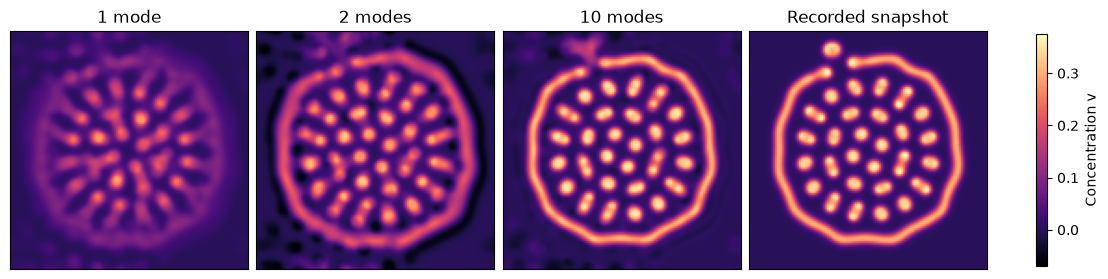

In [8]:
row = 2047
fields = [(mean + spatial[:,:k] @ U_ref[row,:k]).reshape(128,128) for k in (1,2,10)]
fields.append(X[row].reshape(128,128))
lo, hi = min(f.min() for f in fields), max(f.max() for f in fields)
fig, axes = plt.subplots(1,4,figsize=(11,3),layout='constrained')
for ax, field, title in zip(axes,fields,['1 mode','2 modes','10 modes','Recorded snapshot']):
    im=ax.imshow(field,origin='lower',cmap='magma',vmin=lo,vmax=hi)
    ax.set(title=title,xticks=[],yticks=[])
fig.colorbar(im,ax=axes,shrink=.8,label='Concentration v')
plt.show()
del U_all, Xc

## 2. Randomised SVD

The full eigendecomposition computes 4096 directions, although we retain only ten. Its work grows roughly as $n^3$. A product of $A$ with $\ell$ trial vectors costs about $2n^2\ell$ operations. With $\ell=20$, several such products can be much cheaper. We now examine why they help identify the leading directions.

### Sketch and orthonormal basis

We retain $k=10$ directions because they describe about 95% of the variation in this run. Instead of computing every eigenvector of the $4096\times4096$ Gram matrix $A$, we start with $\ell=20$ trial vectors. The extra vectors help capture the leading space; we still plan to retain ten directions at the end.

Each column $\omega$ of $\Omega$ has independent normal entries of mean zero and variance one. The **Gaussian sketch** is $Y=A\Omega$, with shape $4096\times20$.

To see why this multiplication is useful, write $\omega=\sum_i c_i u_i$ in the eigenvector basis. The coefficient $c_i=u_i^T\omega$ is its weight along $u_i$. Then
\[
A\omega=\sum_i\lambda_i c_i u_i.
\]
Larger eigenvalues increase the relative weights of their directions. With $A=\operatorname{diag}(4,1)$ and $\omega=(2,3)^T$, the product is $(8,3)^T$.

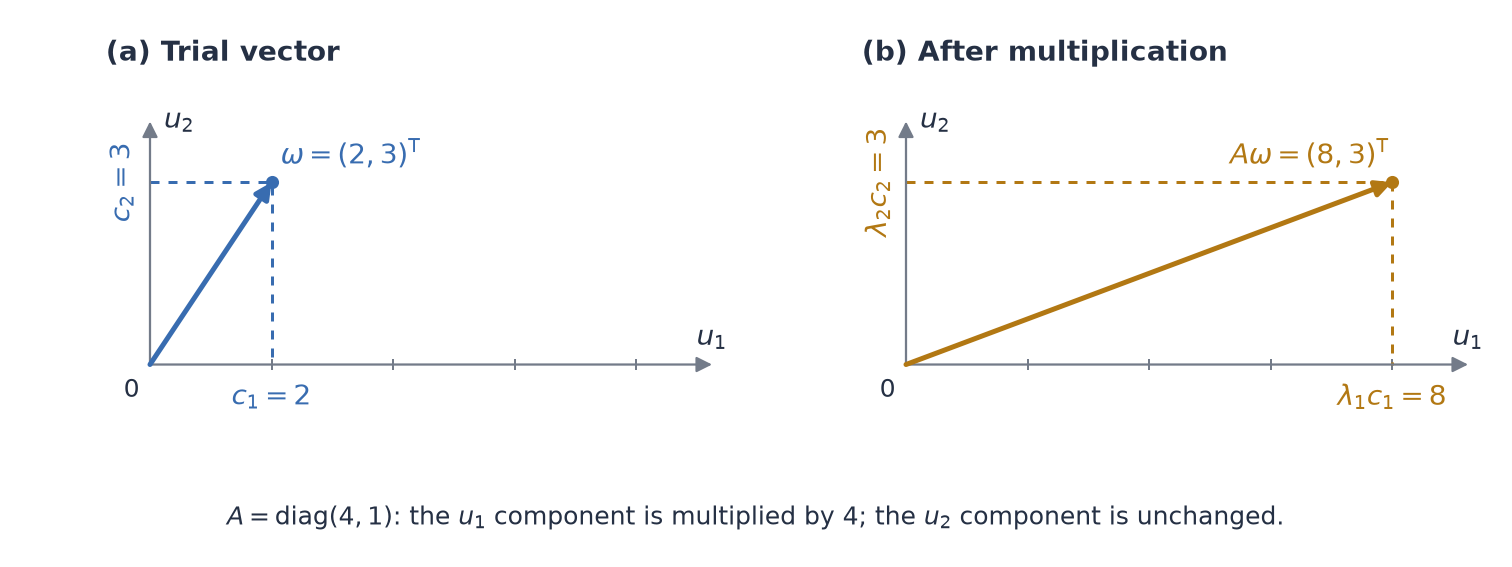

Multiplication by $A=\operatorname{diag}(4,1)$ increases the component along the leading eigenvector from 2 to 8. Both panels use the same axis scale.

The columns of $Y$ need not be perpendicular or have unit length. We want a basis that makes coordinates easy to compute while preserving the vectors that can be formed from those columns.

All weighted sums of a set of vectors form its **span**, a **subspace**. For a matrix, this is its **column space** or **range**. For example, $(1,0,0)^T$ and $(0,1,0)^T$ span the $xy$ plane: their combinations are all vectors $(a,b,0)^T$. An independent set spanning a space is a **basis**.

A **thin QR factorisation** writes $Y=QR$. The columns of $Q$ are an orthonormal basis for the same space: perpendicular and each of length one. The upper-triangular matrix $R$ stores the coefficients needed to recover $Y$. Their shapes are $Q:n\times\ell$ and $R:\ell\times\ell$.

For a vector $a$, $Q^Ta$ contains its inner products with the basis vectors. These are the coordinates of its **orthogonal projection**, the closest vector in the span of $Q$. Multiplying those coordinates by $Q$ returns the projection in the original space.

In [9]:
# A basis for the xy plane and a point outside that plane.
plane_basis = np.eye(3)[:, :2]
point = np.array([2., 3., 4.])
coordinates = plane_basis.T @ point
projection = plane_basis @ coordinates
print('coordinates:', coordinates)
print('projection:', projection)
np.testing.assert_allclose(coordinates, [2., 3.])
np.testing.assert_allclose(projection, [2., 3., 0.])

coordinates: [2. 3.]
projection: [2. 3. 0.]


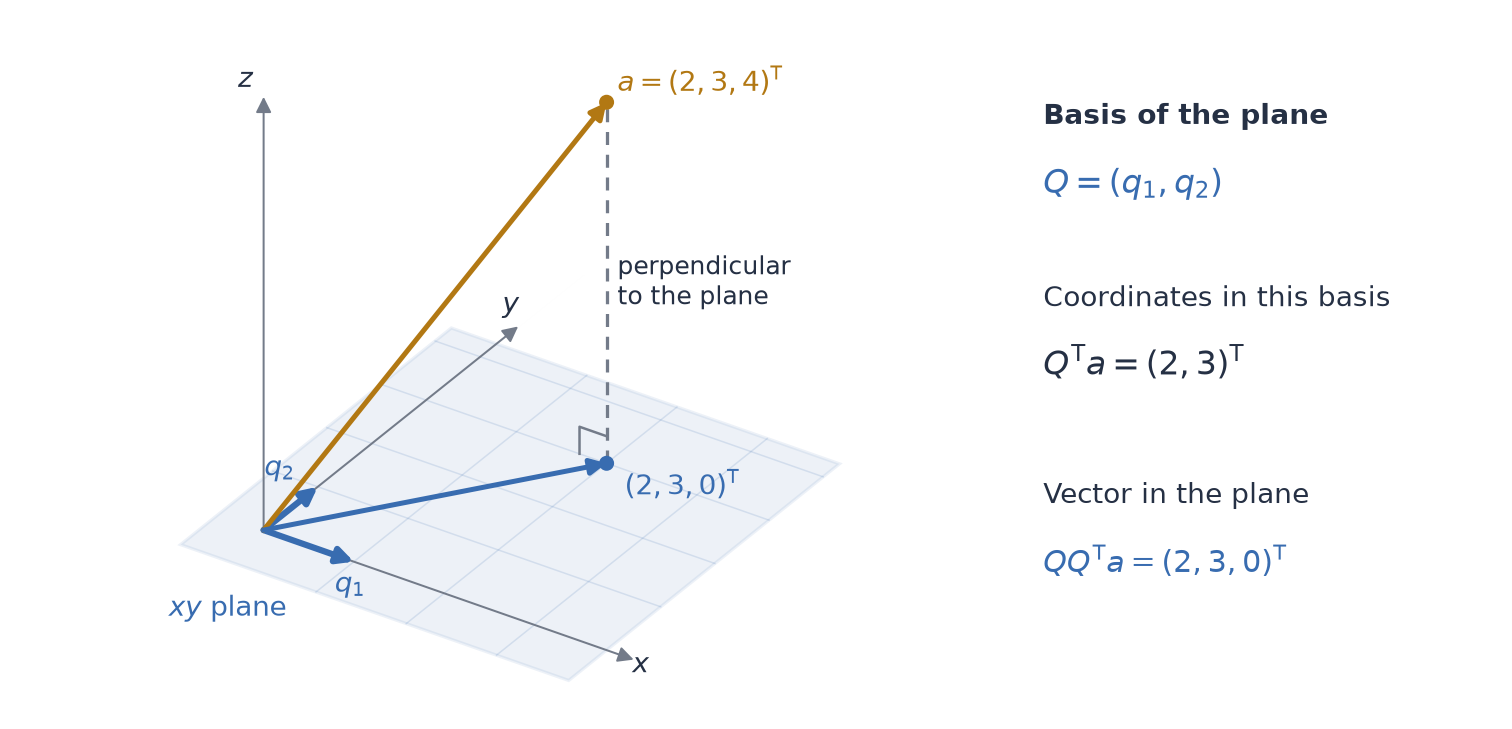

$Q^Ta=(2,3)^T$ gives two coordinates in the plane. $QQ^Ta=(2,3,0)^T$ is the projected vector in three-dimensional space.

### Coordinates of all columns

Applying the same calculation to every column of $A$ gives $Z=Q^TA$, with shape $20\times4096$. Each column of $Z$ holds the 20 coordinates of one projected column of $A$. The colon in $A_{:,j}$ means all rows, keeping column $j$ fixed:
\[
Z_{ij}=q_i^T A_{:,j},\qquad QZ_{:,j}=QQ^T A_{:,j}.
\]
Thus $Z$ uses 20 rows to describe projected vectors that have 4096 entries in the original space.

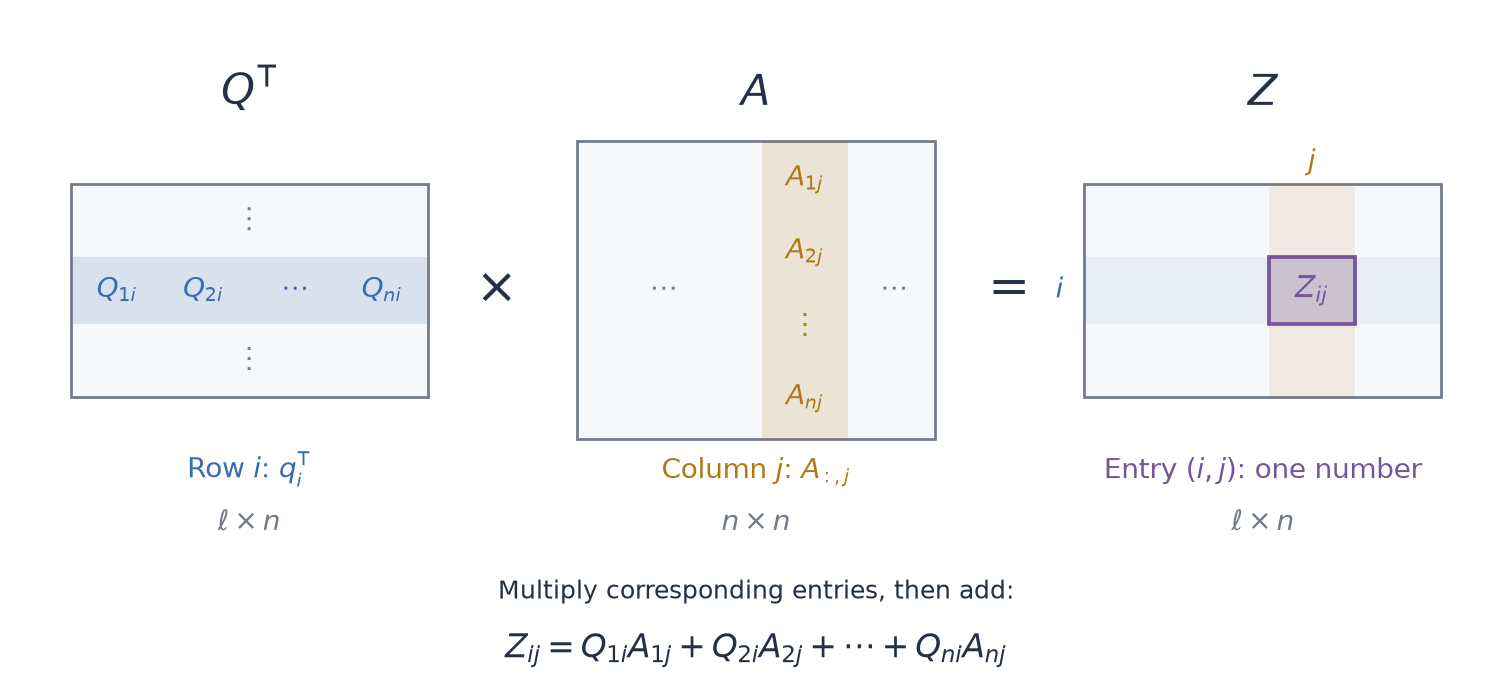

Row $i$ of $Q^T$ dotted with column $j$ of $A$ gives entry $Z_{ij}$. The shapes are $Q^T:20\times4096$, $A:4096\times4096$ and $Z:20\times4096$.

In [10]:
Omega = np.random.default_rng(0).standard_normal((len(A), 20))
Y = A @ Omega
Q, R = np.linalg.qr(Y)
Z = Q.T @ A
print('Y:', Y.shape, 'Q:', Q.shape, 'R:', R.shape)
print('Z:', Z.shape)
np.testing.assert_allclose(Q.T @ Q, np.eye(20), atol=1e-12)
# Python indices start at zero: this is row 3, column 7 of Z.
i, j = 2, 6
print('Z[i, j] and q_i dot A[:, j]:', Z[i, j], Q[:, i] @ A[:, j])
np.testing.assert_allclose(Z[i, j], Q[:, i] @ A[:, j], atol=1e-12)

Y: (4096, 20) Q: (4096, 20) R: (20, 20)
Z: (20, 4096)
Z[i, j] and q_i dot A[:, j]: -0.10991236305330902 -0.10991236305330902


### SVD and truncation

We have 20 coordinates per projected column, but we want to retain only $k=10$ directions. A **singular value decomposition (SVD)** of $Z$ identifies the directions that describe its columns with the smallest total squared approximation error.

The reduced SVD is $Z=\widehat U\Sigma V^T$. The columns of $\widehat U$ and $V$ are orthonormal left and right singular vectors. The diagonal of $\Sigma$ contains non-negative **singular values** $\sigma_i$, largest first. The shapes are $\widehat U:20\times20$, $\Sigma:20\times20$ and $V^T:20\times4096$.

Using all 20 directions reconstructs each column of $Z$:
\[
Z_{:,j}=\sum_{i=1}^{20}\sigma_i V_{ji}\widehat u_i.
\]
Keeping only the first ten terms gives a **truncated SVD**, generally an approximation. The word *reduced* specifies the factor shapes; it does not mean that ten directions have already been discarded.

Multiplying the retained directions by $Q$ gives $U_k=Q\widehat U_{:,1:k}$ in the original space, with shape $4096\times10$. For a positive semi-definite matrix such as $A$, singular values equal eigenvalues. The notebook uses Python's zero-based slice `:k` for the first $k$ columns.

In [11]:
Uh, s, Vh = np.linalg.svd(Z, full_matrices=False)
Z_full = (Uh * s) @ Vh
Z_ten = (Uh[:, :10] * s[:10]) @ Vh[:10]
print('Uh:', Uh.shape, 's:', s.shape, 'Vh:', Vh.shape)
print('all directions reconstruct Z:', np.allclose(Z_full, Z))
print('relative error with ten:', np.linalg.norm(Z - Z_ten) / np.linalg.norm(Z))
np.testing.assert_allclose(Z_full, Z, atol=1e-12)
del Z_full, Z_ten

Uh: (20, 20) s: (20,) Vh: (20, 4096)
all directions reconstruct Z: True
relative error with ten: 0.027405110176722786


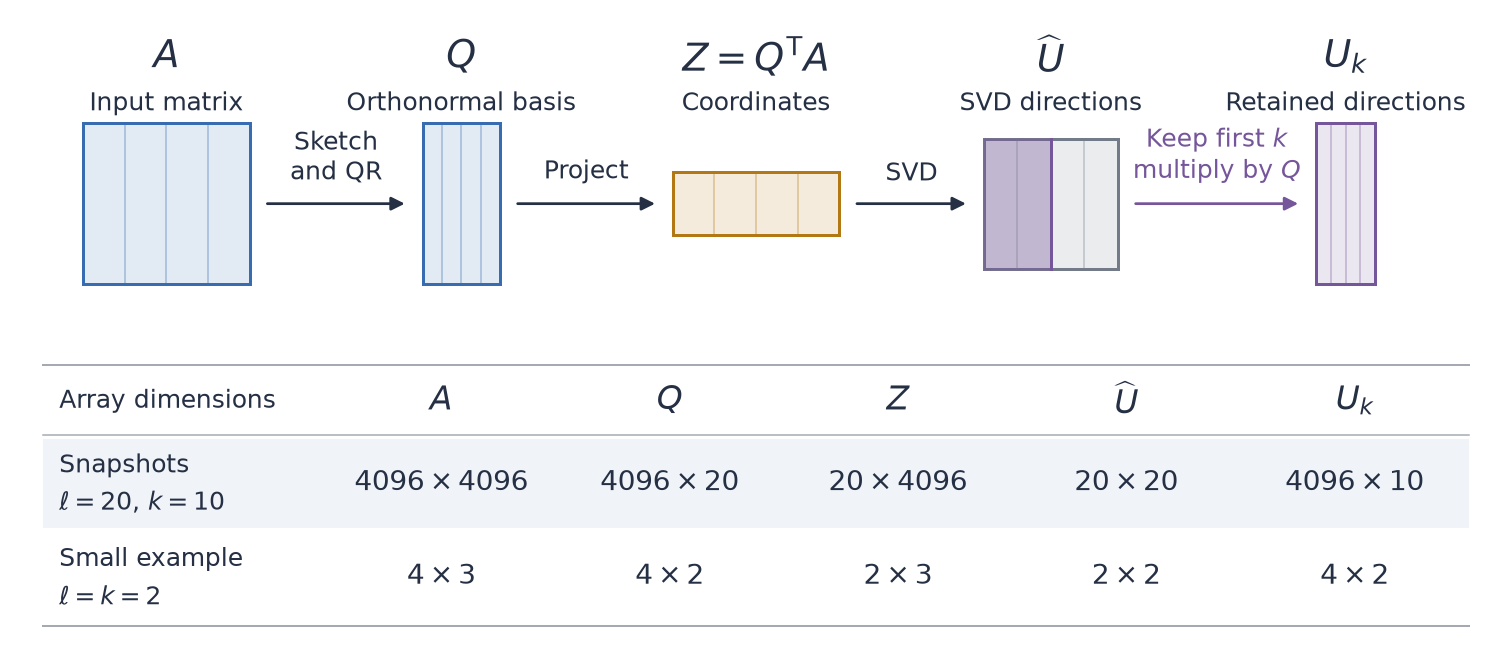

The snapshot calculation uses 20 trial directions and retains ten. In the small rectangular example below, both available directions are retained, so there is no truncation error.

Note that the same construction applies to a rectangular matrix. In this small example, $A$ has shape $4\times3$. Its third column is the sum of its first two independent columns, so its rank is two. Two trial vectors capture its column space.

We put the example in a function so that its local `A` does not replace the snapshot Gram matrix used by the later cells. `s` contains the singular values and `Vh` is $V^T$. Multiplying `Q @ Uh` by `s` scales each column by its singular value.

In [12]:
def rectangular_example():
    A = np.array([[1., 0., 1.], [0., 1., 1.],
                  [1., 1., 2.], [2., 1., 3.]])
    Omega = np.random.default_rng(7).standard_normal((3, 2))
    Q, _ = np.linalg.qr(A @ Omega)
    Z = Q.T @ A
    Uh, s, Vh = np.linalg.svd(Z, full_matrices=False)
    reconstructed = ((Q @ Uh) * s) @ Vh
    print('Z, Uh, Vh:', Z.shape, Uh.shape, Vh.shape)
    print('both directions reconstruct A:', np.allclose(reconstructed, A))
    np.testing.assert_allclose(reconstructed, A, atol=1e-12)

rectangular_example()

Z, Uh, Vh: (2, 3) (2, 2) (2, 3)
both directions reconstruct A: True


### Oversampling and power iterations

**Oversampling** means using more trial vectors than directions retained: here $\ell=k+10$. We can further improve the sketch through repeated multiplication by $A$.

In our recurrence, $q$ counts additional **power iterations**, each using two products with $A$. Leaving out QR for the moment gives
\[
q=0: A\Omega,\qquad q=1:A(A(A\Omega))=A^3\Omega,\qquad q=2:A^5\Omega.
\]
The exponent $2q+1$ counts one initial product and two more per iteration. Along eigenvector $u_i$, the coefficient becomes $\lambda_i^{2q+1}c_i$. This further emphasises directions with larger eigenvalues.

In [13]:
toy_A = np.diag([4., 1.])
omega = np.array([2., 3.])
for q in (0, 1, 2):
    y = toy_A @ omega
    for _ in range(q):
        y = toy_A @ (toy_A @ y)
    print(f'q={q}, exponent={2*q+1}: {y}')

q=0, exponent=1: [8. 3.]
q=1, exponent=3: [128.   3.]
q=2, exponent=5: [2048.    3.]


### Forming a power or multiplying a sketch

We can evaluate $A^3\Omega$ in two ways. **Exact arithmetic** means evaluating each operation without rounding. In exact arithmetic, both ways give the same result. Floating-point operations can round, so we compare the results with a tolerance.

First, we could form the dense matrices $A^2$ and $A^3$:

In [14]:
def form_cube(A, Omega):
    A2 = A @ A
    A3 = A2 @ A
    return A3 @ Omega

Alternatively, we can multiply the sketch three times. Every intermediate `Y` has shape $n\times\ell$:

In [15]:
def multiply_sketch(A, Omega):
    Y = A @ Omega
    Y = A @ Y
    Y = A @ Y
    return Y

# Check equivalence on a small symmetric positive-definite matrix.
rng = np.random.default_rng(4)
B = rng.standard_normal((8, 8))
A_check = B @ B.T + np.eye(8)
Omega_check = rng.standard_normal((8, 3))
np.testing.assert_allclose(form_cube(A_check, Omega_check),
                           multiply_sketch(A_check, Omega_check), rtol=1e-12)
print('The two evaluation orders agree to rounding accuracy.')

The two evaluation orders agree to rounding accuracy.


Two dense products cost about $4n^3$ operations, followed by $2n^2\ell$ for the sketch. Three products with a sketch cost about $6n^2\ell$.

For $n=4096$ and $\ell=20$, forming $A^3$ first costs about 137 times as many operations. In float64, each dense intermediate occupies 128 MiB, compared with 0.625 MiB for a sketch. The next cell computes these counts without allocating the large powers.

In [16]:
n, ell = len(A), 20
F_cube = 4*n**3 + 2*n**2*ell
F_sketch = 6*n**2*ell
print(f'operation ratio: {F_cube/F_sketch:.1f}')
print('dense intermediate:', 8*n**2 / 2**20, 'MiB')
print('sketch intermediate:', 8*n*ell / 2**20, 'MiB')

operation ratio: 136.9
dense intermediate: 128.0 MiB
sketch intermediate: 0.625 MiB


Repeated products can make the sketch columns nearly parallel, allowing smaller components to be lost to rounding. We apply QR initially and after each pair of products. In exact arithmetic, the resulting basis spans the same space as $A^{2q+1}\Omega$, but its entries are different.

The function below implements the coursework recurrence with NumPy. `Omega` is supplied explicitly so that comparisons can reuse the same draw. Including the final projection $Q^TA$, it uses $1+2q+1=2(q+1)$ products involving $A$.

In [17]:
def rsvd(A, k, q, Omega):
    """Approximate k leading eigenvectors of a positive-semidefinite matrix.

    A has shape (n, n); the supplied Gaussian sketch Omega has shape (n, l),
    with k <= l <= n. Perform q pairs of power products, with QR between
    pairs, then an SVD of Q.T @ A. Return an (n, k) orthonormal basis.
    This is the NumPy counterpart of the coursework recurrence.
    """
    Q, _ = np.linalg.qr(A @ Omega)
    for _ in range(q):
        Q, _ = np.linalg.qr(A @ (A @ Q))
    Uh, _, _ = np.linalg.svd(Q.T @ A, full_matrices=False)
    return Q @ Uh[:, :k]

Uk = rsvd(A, k=10, q=2, Omega=Omega)
print('approximate leading vectors:', Uk.shape)
np.testing.assert_allclose(Uk.T @ Uk, np.eye(10), atol=1e-12)

approximate leading vectors: (4096, 10)


For a new problem, we can compare $q=0,1,2$ with a full eigendecomposition on a manageable matrix, keeping `Omega` fixed. We choose the smallest $q$ that meets the accuracy requirement and check it with several draws. Here $q=2$ matches the coursework.

<div style="border-left:4px solid #1b5e20;background:#edf7ed;color:#163c1c;padding:12px 16px;">
<strong>Coursework</strong><br>
The genetic relationship matrix $G$ replaces $A$. Question 1(a) asks for <code>rsvd(G, k, q, Omega)</code> in JAX. Questions 1(b) and 3(b) use $k=10$, $q=2$ and $\ell=20$ to check accuracy and compare execution times. The count $2(q+1)$ enters the models in Question 2(a).
</div>

## 3. Checking the approximation

### Principal angles

Before comparing times, we should check whether the approximate vectors describe the same directions as a reference calculation. Comparing their entries directly can reject a correct result: if $Au=\lambda u$, then $A(-u)=\lambda(-u)$ as well.

The eigenvectors of an eigenvalue, together with zero, form its **eigenspace**. A repeated eigenvalue can allow different orthonormal bases of the same plane. We therefore compare the spaces spanned by the columns.

For two lines represented by unit vectors $u,v$, the smaller angle is
\[
\theta=\arccos|u^Tv|,\qquad 0\leq\theta\leq90^\circ.
\]
The absolute value removes the choice of sign. The inverse cosine returns the angle.

For two orthonormal bases $U,V$ of $k$-dimensional spaces, $U^TV$ contains the pairwise inner products of the basis vectors. Its singular values $\sigma_i$ define the **principal angles** by $\theta_i=\arccos\sigma_i$. The angles do not depend on the choice of orthonormal bases. When all are zero, the spaces coincide.

The supplied helper returns radians, smallest first. We use `np.degrees` to display degrees; $\pi$ radians correspond to $180^\circ$.

In [18]:
def principal_angles(U, V):
    """The principal angles between the column spans of U and V, in radians, smallest first.

    U and V have orthonormal columns and the same shape (n, k). The cosines of
    the angles are the singular values of U^T V. Their sines are the singular
    values of V - U U^T V, which resolve small angles more accurately.

    Examples
    --------
    >>> U = np.eye(3)[:, :2]
    >>> principal_angles(U, -U[:, ::-1])         # other signs and order, same plane
    array([0., 0.])
    >>> v = np.array([[0.5], [np.sqrt(3) / 2], [0.0]])
    >>> np.degrees(principal_angles(U[:, :1], v)).round(6)
    array([60.])
    """
    M = U.T @ V
    cos = np.linalg.svd(M, compute_uv=False)                  # largest first
    sin = np.linalg.svd(V - U @ M, compute_uv=False)[::-1]    # smallest first
    return np.where(cos**2 < 0.5, np.arccos(np.minimum(cos, 1.0)),
                    np.arcsin(np.minimum(sin, 1.0)))

For a worked example, let $U$ span the $xy$ plane. Reversing its signs and column order gives the same plane. We then tilt one basis vector by $30^\circ$ towards the $z$ axis to form $W$:

In [19]:
U = np.eye(3)[:, :2]
V = -U[:, ::-1]
t = np.radians(30)
W = np.column_stack([U[:, 0], [0., np.cos(t), np.sin(t)]])
print('same columns:', np.allclose(U, V))
print('same plane:', np.degrees(principal_angles(U, V)))
print('U.T @ W:')
print((U.T @ W).round(6))
print('tilted plane:', np.degrees(principal_angles(U, W)).round(6))
np.testing.assert_allclose(np.degrees(principal_angles(U, W)), [0, 30], atol=1e-12)

same columns: False
same plane: [0. 0.]
U.T @ W:
[[1.       0.      ]
 [0.       0.866025]]
tilted plane: [ 0. 30.]


Here $U^TW=\operatorname{diag}(1,\cos30^\circ)$. Its singular values give angles of $0^\circ$ and $30^\circ$. One direction agrees exactly; the other is tilted.

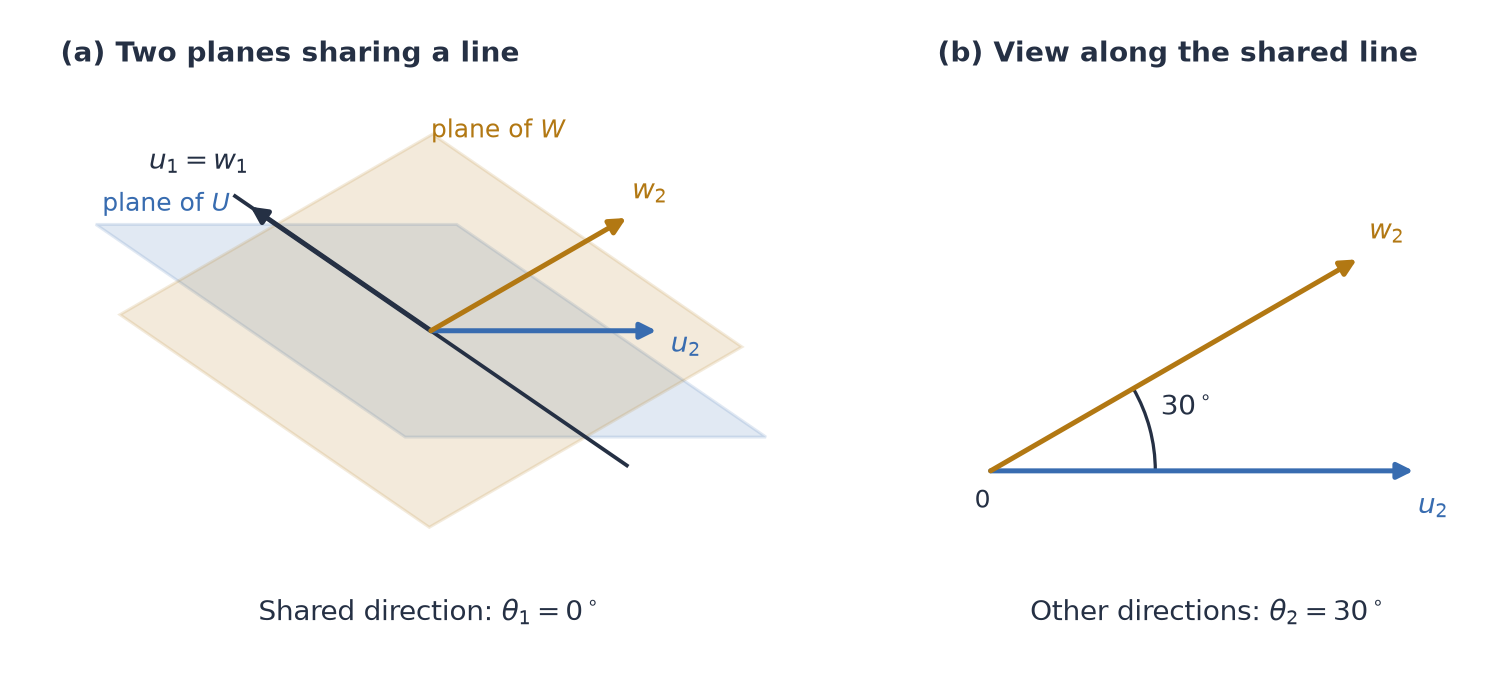

The two planes share the direction $u_1=w_1$. Looking along this line shows the remaining angle, $30^\circ$.

For an accuracy test, we use the largest principal angle. Imagine choosing a direction in the approximate space and finding the closest direction in the reference space. The largest angle over all such choices is the largest principal angle. A value below $1^\circ$ means that every approximate direction is within $1^\circ$ of the reference space.

**Principal angles do not check column order.** Swapping two eigenvectors leaves their span unchanged, so a promise about eigenvalue ordering needs a separate test.

### Reference calculation and fixed seeds

We first choose a small matrix whose leading eigenvectors are known. A diagonal matrix with decreasing positive entries has the first four coordinate vectors as its leading four eigenvectors. `np.geomspace` generates values with a constant ratio between neighbours, and `np.diag` places them on the diagonal.

For $k=4$, our oversampling rule gives $\ell=14$. We require the largest angle to be below one degree and the returned columns to be orthonormal. We repeat this check with five random draws:

In [20]:
C = np.diag(np.geomspace(1., 1e-6, 60))
reference = np.eye(60)[:, :4]
for seed in range(5):
    trial = np.random.default_rng(seed).standard_normal((60, 14))
    result = rsvd(C, k=4, q=2, Omega=trial)
    angle = np.degrees(principal_angles(reference, result)).max()
    print(f'seed {seed}: {angle:.6f} degrees')
    assert angle < 1.0
    np.testing.assert_allclose(result.T @ result, np.eye(4), atol=1e-12)

seed 0: 0.000588 degrees
seed 1: 0.000194 degrees
seed 2: 0.000082 degrees
seed 3: 0.000403 degrees
seed 4: 0.000162 degrees


The angle checks accuracy. The second assertion checks lengths and inner products: orthonormal columns give the identity matrix. Reusing a seed reproduces that draw in this environment, so a failing case can be rerun. These tests establish agreement for the chosen inputs and tolerance.

For the snapshot matrix, the reference is the full eigendecomposition already stored in `U_ref`. We check the angle and reconstruct the same snapshot using the approximate directions:

snapshot approximation: largest angle 0.003477 degrees


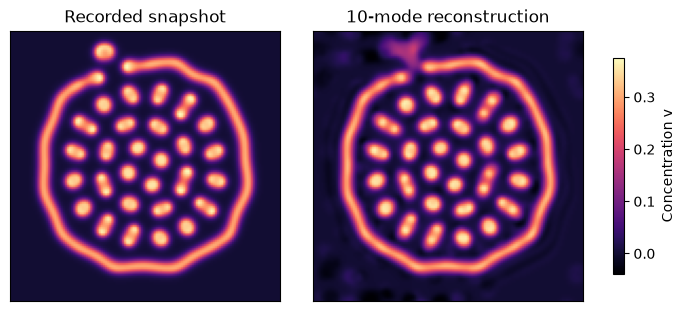

In [21]:
angle = np.degrees(principal_angles(U_ref, Uk)).max()
print(f'snapshot approximation: largest angle {angle:.6f} degrees')
assert angle < 1.0
row = 2047
Xc = X - mean
approximate_modes = Xc.T @ Uk
reconstructed = mean + approximate_modes @ Uk[row]
del Xc
original = X[row]
lo, hi = min(original.min(), reconstructed.min()), max(original.max(), reconstructed.max())
fig, axes = plt.subplots(1, 2, figsize=(7, 3), layout='constrained')
for ax, field, title in zip(axes, (original, reconstructed), ('Recorded snapshot', '10-mode reconstruction')):
    im = ax.imshow(field.reshape(128, 128), origin='lower', cmap='magma', vmin=lo, vmax=hi)
    ax.set(title=title, xticks=[], yticks=[])
fig.colorbar(im, ax=axes, label='Concentration v', shrink=.8)
plt.show()

### QR during the power iterations

The same test can show why we use QR before the final SVD. We compare two float32 calculations with identical inputs: one applies QR only after all the products, and one uses QR initially and after each pair. Both approximate the same space in exact arithmetic. The reference remains the full float64 eigendecomposition.

In [22]:
A32, O32 = A.astype(np.float32), Omega.astype(np.float32)
Y = A32 @ O32
for _ in range(2):
    Y = A32 @ (A32 @ Y)
Q32, _ = np.linalg.qr(Y)
Uh32, _, _ = np.linalg.svd(Q32.T @ A32, full_matrices=False)
plain = Q32 @ Uh32[:, :10]
stable = rsvd(A32, 10, 2, O32)
for name, result in [('QR only at end', plain), ('QR between iterations', stable)]:
    angle = np.degrees(principal_angles(U_ref, result.astype(float))).max()
    print(f'{name:24s} {angle:.4f} degrees')
assert np.degrees(principal_angles(U_ref, stable.astype(float))).max() < 1.0
del A32, O32, Y, Q32, Uh32, plain, stable

QR only at end           80.1575 degrees
QR between iterations    0.0035 degrees


The lecture run gave about 80 degrees with QR only at the end, compared with 0.0035 degrees with QR between pairs. The values above come from this execution. QR between iterations preserves enough accuracy for this matrix; more demanding cases can need QR after every individual product ([Halko, Martinsson and Tropp, Algorithm 4.4](https://arxiv.org/abs/0909.4061)).

## 4. Cost and performance

### Operation counts and timings

We count an addition or multiplication as one floating-point operation. Multiplying $2(q+1)$ products by $2n^2\ell$ operations per product gives
\[
F_{\mathrm{rsvd}}\approx4(q+1)n^2\ell.
\]
This leading count omits QR and the SVD of $Z$, whose costs grow as $n\ell^2$ for fixed $q$.

The coursework's full-eigensolver model is $F_{\mathrm{eigh}}\approx9n^3$, from the classical symmetric QR estimate in §1.4 of the notes. NumPy uses LAPACK's divide-and-conquer solver. The operation ratio compares these models; the measured speed-up is a separate ratio of times.

We prepare inputs before timing, make one untimed warm-up call, and report the median of three calls. These times belong to the computer executing this notebook.

In [23]:
n, ell, q = len(A), 20, 2
F_rsvd, F_eigh = 4*(q+1)*n**2*ell, 9*n**3
t_eigh = seconds(leading_eigh, A, 10)
t_rsvd = seconds(rsvd, A, 10, q, Omega)
print(f'eigh: {t_eigh:.3f} s; rsvd: {1000*t_rsvd:.2f} ms')
print(f'model operation ratio: {F_eigh/F_rsvd:.1f}')
print(f'measured speed-up: {t_eigh/t_rsvd:.1f}')

eigh: 4.478 s; rsvd: 17.45 ms
model operation ratio: 153.6
measured speed-up: 256.6


### Bytes and storage widths

We model **memory traffic** by reading each input once and writing its output once. Actual transfers depend on cache reuse. Let $D$ be this byte count and $I=F/D$ the **arithmetic intensity**, measured in FLOP/byte.

For $A\Omega$, with $b$ bytes per value,
\[
D=bn^2+bn\ell+bn\ell.
\]
The terms are the read of $A$, the read of $\Omega$ and the write of $A\Omega$. Neglecting the small arrays gives $D\approx bn^2$. Across all $2(q+1)$ products,
\[
D_{\mathrm{rsvd}}\approx2(q+1)bn^2,\qquad I_{\mathrm{rsvd}}\approx2\ell/b.
\]
For $\ell=20$ and $b=8$, this is five operations per byte. Increasing $q$ adds the same kinds of products, increasing work and transfers together.

In [24]:
b = 8
D_product = b*(n**2 + 2*n*ell)
D_rsvd = 2*(q+1)*b*n**2
print('one product, including both sketches:', D_product, 'bytes')
print('rsvd leading count:', D_rsvd, 'bytes')
print('rsvd intensity:', F_rsvd/D_rsvd, 'FLOP/byte')

one product, including both sketches: 135528448 bytes
rsvd leading count: 805306368 bytes
rsvd intensity: 5.0 FLOP/byte


For the full eigensolver, the coursework counts only the input, $D\approx bn^2$. This omits workspace, intermediate eigenvectors and repeated transfers; it is a comparison convention rather than a measurement of NumPy's traffic.

When stored dtypes differ, count each array separately. For $M:m\times r$, $N:r\times s$ and $C=MN:m\times s$,
\[
F\approx2mrs,\qquad D=b_Mmr+b_Nrs+b_Cms.
\]
An output entry takes $r$ multiplications and $r-1$ additions. In the following example, the inputs use bf16 (two bytes per value) and the output uses float32 (four bytes). We compute the byte counts without requiring NumPy to execute a bf16 product.

In [25]:
m, r, s = 2048, 1024, 32
F = 2*m*r*s
parts = {'read M': 2*m*r, 'read N': 2*r*s, 'write C': 4*m*s}
for name, value in parts.items():
    print(f'{name}: {value:,} bytes')
D = sum(parts.values())
print(f'total: {D:,} bytes; intensity: {F/D:.1f} FLOP/byte')
assert D == 4521984

read M: 4,194,304 bytes
read N: 65,536 bytes
write C: 262,144 bytes
total: 4,521,984 bytes; intensity: 29.7 FLOP/byte


The stored dtypes determine bytes, while additions can use a wider format, such as a float32 running sum for bf16 products.

For the Gram matrix $A=X_cX_c^T/p$, both operands refer to the same input. The coursework counts that input once and the output once:
\[
F\approx2n^2p,\qquad D=b_Xnp+b_An^2.
\]
This neglects the divisions by $p$, assumes reuse of the input and omits intermediate arrays. At fixed $p$, doubling $n$ doubles the input size, but multiplies the output size and leading work by four.

### Roofline and performance estimates

A **kernel** here is the calculation being timed, such as $A\Omega$. A processor with arithmetic rate $P_{\max}$ FLOP/s needs at least $F/P_{\max}$ seconds for the operations. Bandwidth $W_{\max}$ bytes/s gives a transfer time of $D/W_{\max}$. They may overlap, but both must finish. We take the larger time:
\[
t_{\rm roof}=\max(F/P_{\max},D/W_{\max}),\qquad R_{\rm roof}(I)=\min(P_{\max},IW_{\max}).
\]
At the **ridge point** $I^*=P_{\max}/W_{\max}$, the two times are equal. Below it the model is **memory-bound**, and above it **compute-bound**.

For the worked example we use previously measured laptop reference rates, $P_{\max}=787$ GFLOP/s and $W_{\max}=307$ GB/s. These give an **empirical roofline**, not strict hardware bounds. In the code, `P_max` and `W_max` denote these rates. G means $10^9$.

In [26]:
P_max, W_max = 787e9, 307e9
F_product = 2*n**2*ell
D_leading = 8*n**2
arithmetic_time = F_product/P_max
transfer_time = D_leading/W_max
roof_time = max(arithmetic_time, transfer_time)
print(f'ridge: {P_max/W_max:.2f} FLOP/byte')
print(f'arithmetic: {arithmetic_time*1000:.3f} ms')
print(f'transfers:  {transfer_time*1000:.3f} ms')
print(f'model time: {roof_time*1000:.3f} ms (compute-bound)')
t_example = 1.80e-3
print(f'if measured time is 1.80 ms: {F_product/t_example/1e9:.1f} GFLOP/s')
print(f'percentage of reference rate: {100*F_product/t_example/P_max:.1f}%')

ridge: 2.56 FLOP/byte
arithmetic: 0.853 ms
transfers:  0.437 ms
model time: 0.853 ms (compute-bound)
if measured time is 1.80 ms: 372.8 GFLOP/s
percentage of reference rate: 47.4%


The roof rises as $R=IW_{\max}$ up to the ridge, then stays at $R=P_{\max}$. We plot both axes logarithmically.

The following figure reproduces the recorded lecture-laptop measurements. These are distinct from the live timings above. A plotted point has coordinates $(F/D,F/t)$. The full eigensolver uses the prescribed QR work count; its plotted rate does not measure NumPy's actual arithmetic rate or hardware utilisation.

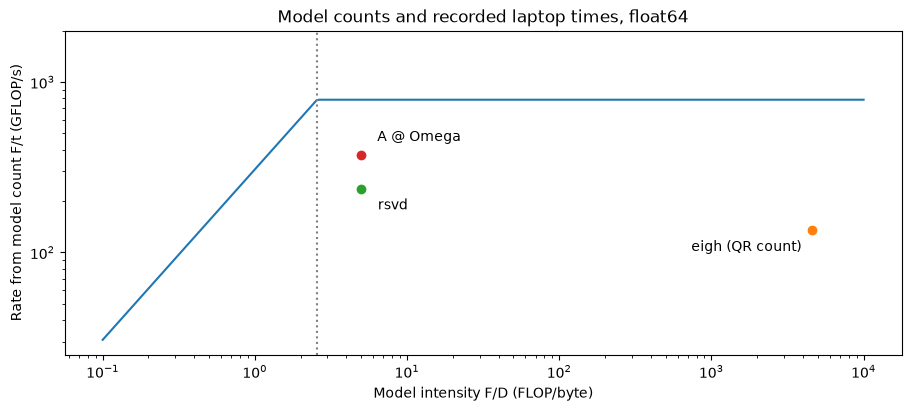

In [27]:
recorded = [{'name': 'eigh', 'F': 618475290624, 'D': 134217728, 't': 4.578256166016217, 'I': 4608.0, 'R': 135089708438.5228}, {'name': 'rsvd', 'F': 4026531840, 'D': 805306368, 't': 0.016981291002593935, 'I': 5.0, 'R': 237115766956.99622}, {'name': 'A @ Omega', 'F': 671088640, 'D': 135528448, 't': 0.0017965000006370246, 'I': 4.951644100580271, 'R': 373553375876.44714}]
intensities = np.logspace(-1, 4, 300)
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
ax.loglog(intensities, np.minimum(P_max, intensities*W_max)/1e9)
ax.axvline(P_max/W_max, ls=':', color='grey')
for row, offset in zip(recorded, [(-8, -15), (12, -15), (12, 10)]):
    ax.plot(row['I'], row['R']/1e9, 'o')
    label = 'eigh (QR count)' if row['name'] == 'eigh' else row['name']
    ax.annotate(label, (row['I'], row['R']/1e9), xytext=offset,
                textcoords='offset points', ha='right' if offset[0] < 0 else 'left')
ax.set(xlabel='Model intensity F/D (FLOP/byte)', ylabel='Rate from model count F/t (GFLOP/s)',
       title='Model counts and recorded laptop times, float64', ylim=(25, 2000))
plt.show()

The isolated product is closer to the roof than the full randomised SVD. The latter's measured time includes QR and SVD work omitted from the leading count. For a memory-bound calculation, a low percentage of the arithmetic peak may instead reflect the bandwidth limit. A point below the roof identifies a gap from the model, but does not by itself establish the cause.

### Sketch width and scaling

Each column of $\Omega$ is a trial vector. Processing them together is **batching**: values of $A$ can be reused across columns. Including both sketch arrays gives
\[
I(\ell)=\frac{2n^2\ell}{b(n^2+2n\ell)}.
\]
For $\ell\ll n$, this is approximately $2\ell/b$. The main transfer cost remains reading $A$, while arithmetic grows with $\ell$.

Solving $I(\ell^*)=I^*$ gives the model transition width
\[
\ell^*=\frac{I^*bn}{2n-2bI^*},\qquad n>bI^*.
\]
If $n\leq bI^*$, the intensity never reaches the ridge at a finite width. For $n=4096$ and the float64 laptop references, $\ell^*\approx10.3$.

reference transition width: 10.3


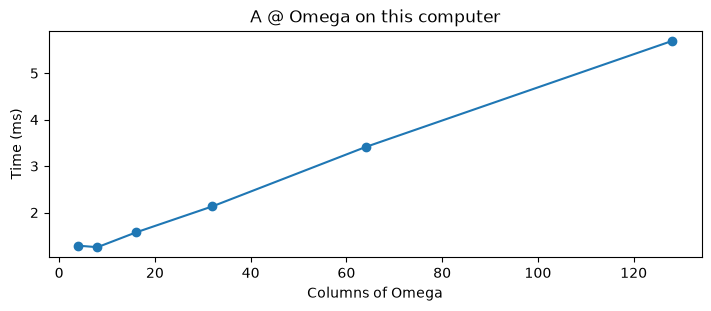

In [28]:
ridge = P_max/W_max
width_at_ridge = ridge*8*n/(2*n - 2*8*ridge)
print(f'reference transition width: {width_at_ridge:.1f}')
widths = [4, 8, 16, 32, 64, 128]
times = []
for width in widths:
    trial = np.random.default_rng(0).standard_normal((n, width))
    times.append(seconds(np.matmul, A, trial))
fig, ax = plt.subplots(figsize=(7, 3), layout='constrained')
ax.plot(widths, 1000*np.array(times), 'o-')
ax.set(xlabel='Columns of Omega', ylabel='Time (ms)', title='A @ Omega on this computer')
plt.show()

The curve above uses local timings. When transfers dominate, nearby widths can have similar times. A wider sketch can reuse $A$ more effectively, but its width also affects approximation accuracy.

We can separately vary the number of snapshots $n$. At fixed $q,\ell$, the randomised method's leading work grows as $n^2$ and the full eigensolver model as $n^3$. Doubling $n$ multiplies those counts by four and eight.

If time scales as $n^\rho$, then $t(2n)/t(n)=2^\rho$, so
\[
\widehat\rho=\frac{\log[t(2n)/t(n)]}{\log2}.
\]
The next cell uses the two recorded timings supplied in the notes' scaling exercise. It does not fit the sketch-width timings above, which vary $\ell$ rather than $n$.

In [29]:
t_small, t_large = 72.3e-3, 567e-3
print('time ratio:', round(t_large/t_small, 2))
print('estimated exponent:', round(math.log2(t_large/t_small), 2))

time ratio: 7.84
estimated exponent: 2.97


The exponent is close to three for this pair of sizes. With more sizes, we fit a line to $\log t$ against $\log n$. Cache reuse and library overheads can make the measured exponent differ from the leading work exponent.

### Capacity exercise

For the notes' separate memory-budget exercise, store $n$ snapshots of $p=16384$ values in float32 and their Gram matrix in float64. Their combined size is $4np+8n^2$ bytes. We solve $4np+8n^2\leq16\times10^9$ for the largest integer $n$:

In [30]:
p, budget = 16384, 16e9
n_max = math.floor((-4*p + math.sqrt((4*p)**2 + 32*budget))/16)
print('maximum snapshots:', n_max)
assert 4*n_max*p + 8*n_max**2 <= budget
assert 4*(n_max+1)*p + 8*(n_max+1)**2 > budget

maximum snapshots: 40812
